# Иерархическая агломеративная кластеризация данных

## 1. Формулировка задания
1. Создать программу для выполнения агломеративной иерархической кластеризации набора данных.
   - Параметры программы: набор данных, мера схожести кластеров (Single linkage, Complete linkage, Group average, Ward distance).
   - Расстояние между объектами: Евклидова метрика ($L_2$).
   - Визуализация: построение дендрограмм для каждого метода связи.
2. Исследование мер схожести (linkage criteria):
   - Построить дендрограммы и оценить структуру кластеров для различных методов связывания.
   - Оценить качество сохранения метрических расстояний с помощью коэффициента кофенетической корреляции (Cophenetic Correlation Coefficient).
   - Сравнить структуру разбиений на k=4 кластера с помощью метрики силуэта (Silhouette Score).
3. Сравнение с разделительной кластеризацией:
   - Сопоставить результаты иерархической кластеризации (прежде всего метода Ward) с результатами алгоритмов k-Means и k-Medoids из предыдущей лабораторной работы.
   - Проанализировать вычислительную сложность, чувствительность к шуму и применимость в реальных задачах сегментации клиентов.

## 2. Ссылка на репозиторий
Каталог репозиторий: `https://github.com/GeRoNioPLAY/Data_analysis`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

## 3. Загрузка и предобработка данных

In [2]:
df = pd.read_csv("../lab5/customers.csv")

drop_cols = [c for c in ["Row", "CustomerId"] if c in df.columns]
features_df = df.drop(columns=drop_cols)

if features_df.isnull().sum().sum() > 0:
    features_df = features_df.fillna(features_df.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_df)
feature_names = features_df.columns.tolist()

print(
    f"Размерность выборки: {X_scaled.shape[0]} объектов, {X_scaled.shape[1]} признаков"
)
print(f"Список признаков: {feature_names}")

Размерность выборки: 850 объектов, 8 признаков
Список признаков: ['Age', 'Education', 'YearsEmployed', 'Income', 'CardDebt', 'OtherDebt', 'Defaulted', 'DebtIncomeRatio']


## 4. Построение дендрограмм для различных мер схожести кластеров

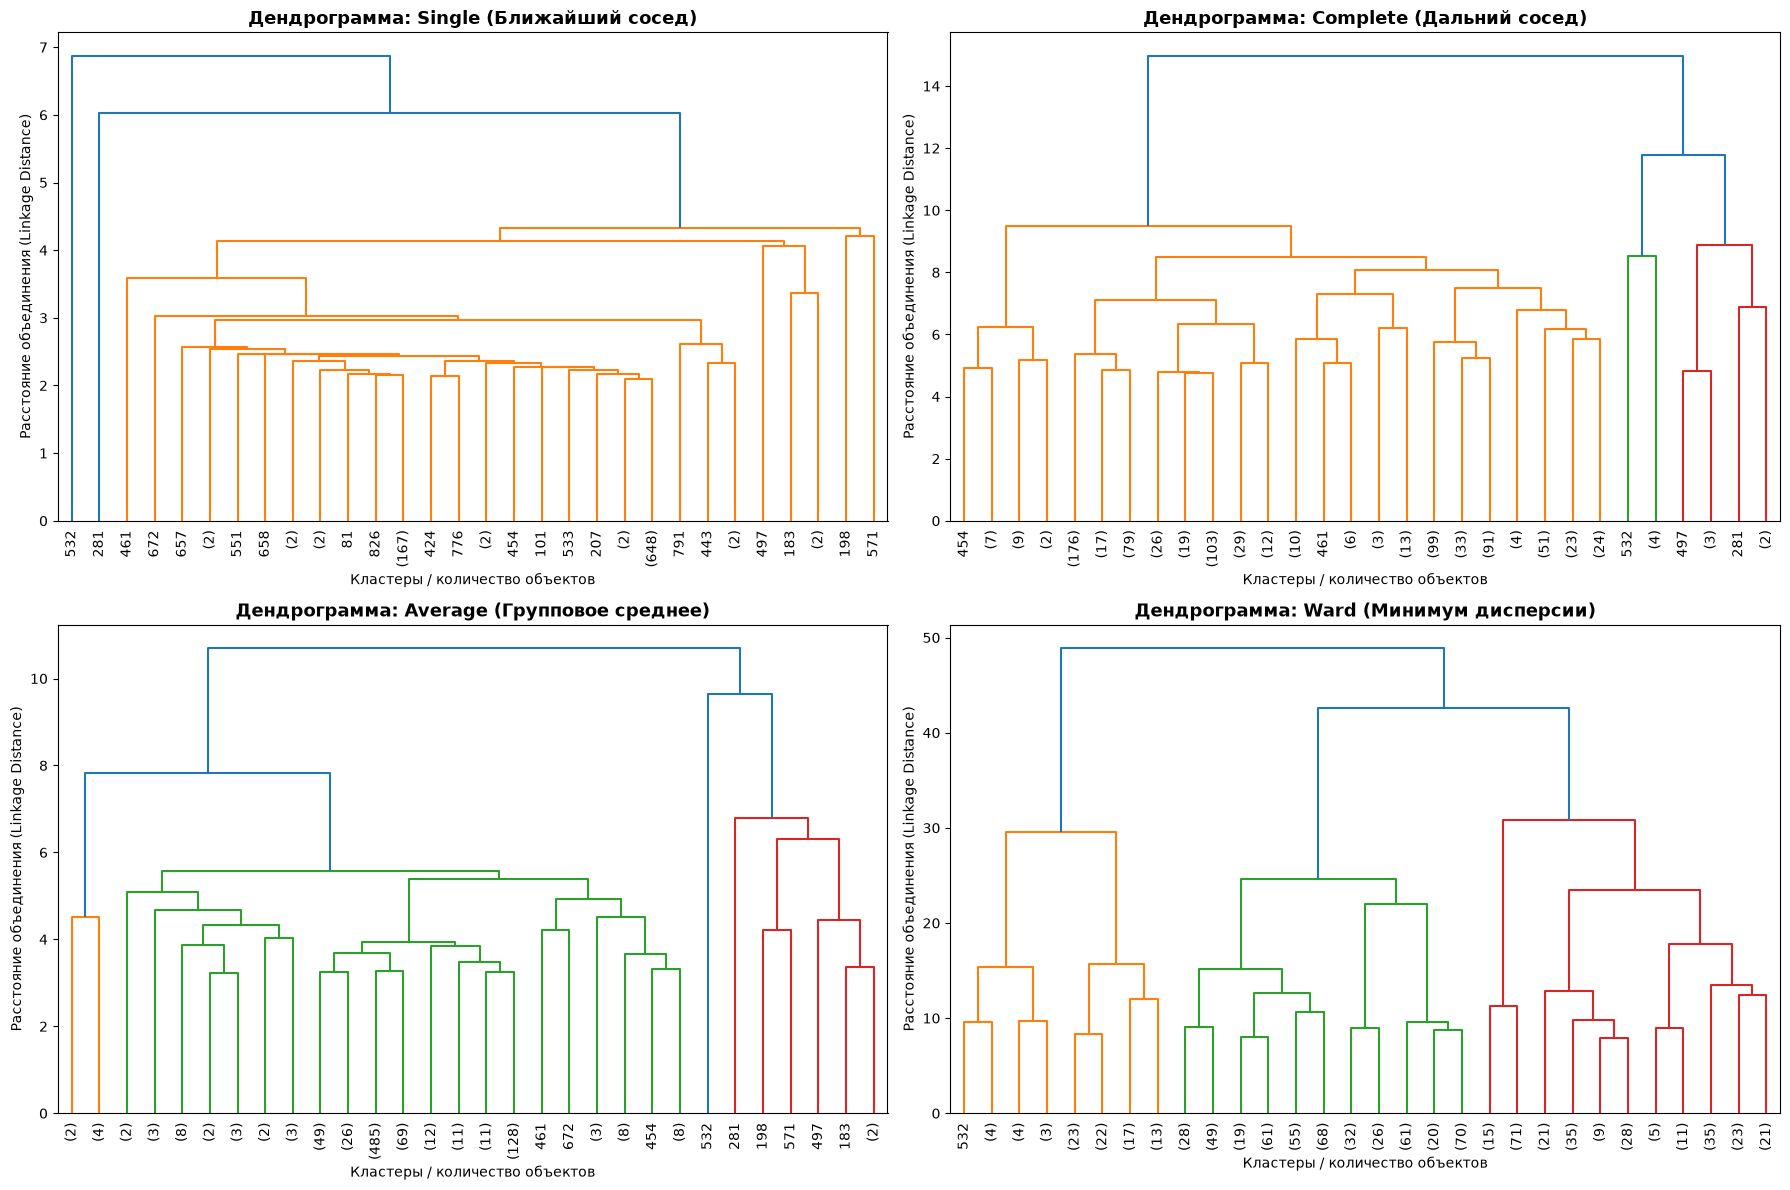

In [3]:
linkage_methods = {
    "Single (Ближайший сосед)": "single",
    "Complete (Дальний сосед)": "complete",
    "Average (Групповое среднее)": "average",
    "Ward (Минимум дисперсии)": "ward",
}

linkage_matrices = {}

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

for i, (title, method) in enumerate(linkage_methods.items()):
    Z = linkage(X_scaled, method=method, metric="euclidean")
    linkage_matrices[method] = Z

    dendrogram(
        Z,
        ax=axes[i],
        truncate_mode="lastp",
        p=30,
        show_leaf_counts=True,
        leaf_rotation=90,
        leaf_font_size=10,
    )
    axes[i].set_title(f"Дендрограмма: {title}", fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Кластеры / количество объектов")
    axes[i].set_ylabel("Расстояние объединения (Linkage Distance)")

plt.tight_layout()
plt.show()

## 5. Количественное сравнение мер схожести кластеров

In [4]:
distances = pdist(X_scaled, metric="euclidean")

k_eval = 4
metrics_data = []

labels_dict = {}

for title, method in linkage_methods.items():
    Z = linkage_matrices[method]

    coph_corr, _ = cophenet(Z, distances)

    labels = fcluster(Z, t=k_eval, criterion="maxclust")
    labels_dict[method] = labels

    sil_score = silhouette_score(X_scaled, labels)

    cluster_counts = pd.Series(labels).value_counts().sort_index().to_dict()

    metrics_data.append(
        {
            "Метод связи": title,
            "Cophenetic Correlation": round(coph_corr, 4),
            "Silhouette Score (k=4)": round(sil_score, 4),
            "Размеры кластеров (k=4)": str(list(cluster_counts.values())),
        }
    )

comparison_df = pd.DataFrame(metrics_data)
display(comparison_df)

,Метод связи,Cophenetic Correlation,Silhouette Score (k=4),Размеры кластеров (k=4)
0,Single (Ближайший сосед),0.7416,0.6421,"[846, 2, 1, 1]"
1,Complete (Дальний сосед),0.6550,0.3384,"[19, 819, 5, 7]"
2,Average (Групповое среднее),0.8555,0.5478,"[6, 836, 7, 1]"
3,Ward (Минимум дисперсии),0.5563,0.2264,"[87, 489, 86, 188]"


## 6. Двумерная визуализация кластеров при k = 4 для всех методов связи

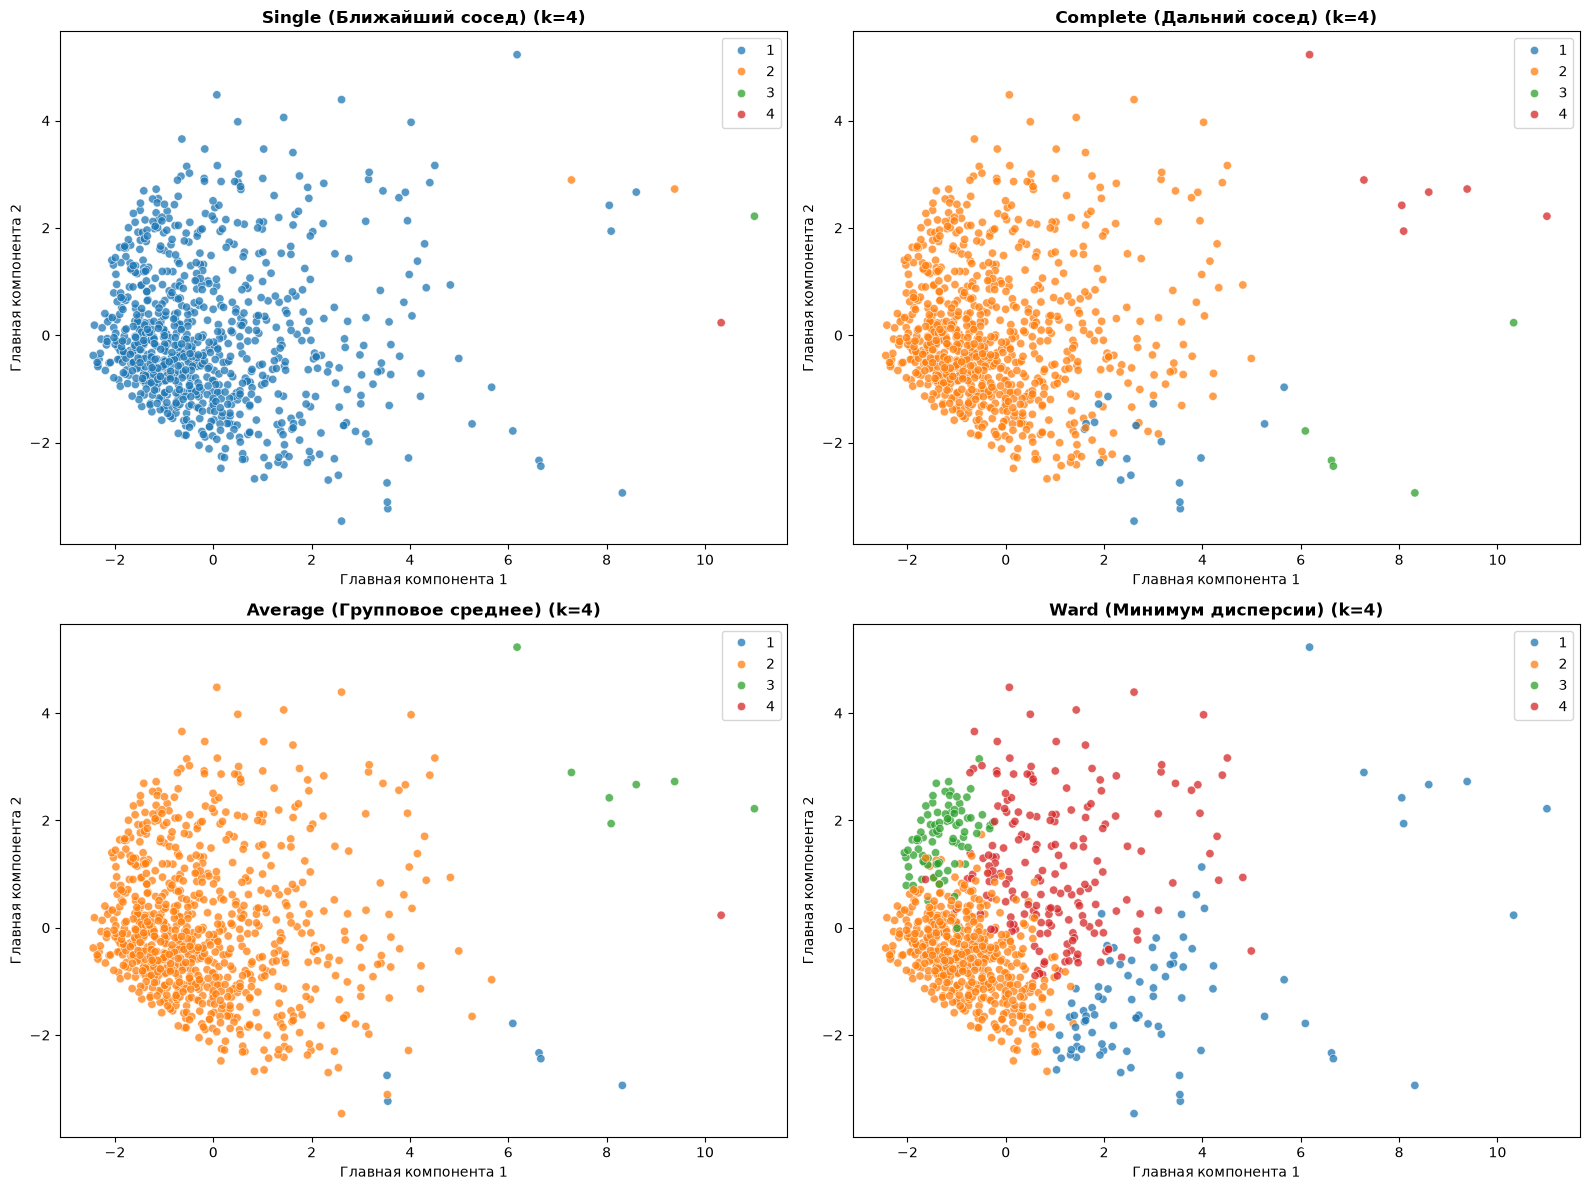

In [5]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (title, method) in enumerate(linkage_methods.items()):
    labels = labels_dict[method]
    sns.scatterplot(
        x=X_pca[:, 0],
        y=X_pca[:, 1],
        hue=labels,
        palette="tab10",
        ax=axes[i],
        alpha=0.75,
        legend="full",
    )
    axes[i].set_title(f"{title} (k={k_eval})", fontsize=12, fontweight="bold")
    axes[i].set_xlabel("Главная компонента 1")
    axes[i].set_ylabel("Главная компонента 2")

plt.tight_layout()
plt.show()

## 7. Сравнение иерархической кластеризации с алгоритмами k-Means и k-Medoids

Сравнительная таблица моделей (k=4):


,Алгоритм,Silhouette Score,ARI относительно Ward
0,Hierarchical (Ward),0.2264,1.0000
1,k-Means,0.2470,0.4798
2,k-Medoids,0.1634,0.2285


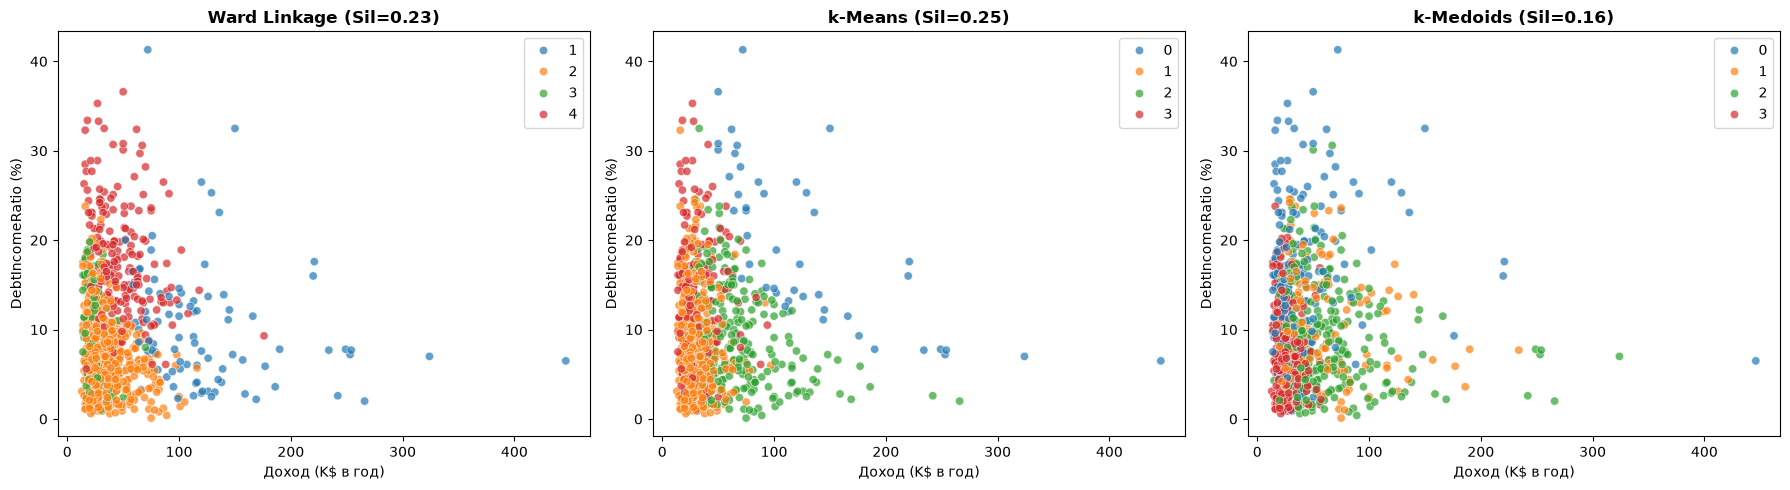

In [6]:
kmeans = KMeans(n_clusters=k_eval, random_state=42, n_init=10).fit(X_scaled)
km_labels = kmeans.labels_

from scipy.spatial.distance import cdist

dist_mat = cdist(X_scaled, X_scaled)
medoids = np.random.RandomState(42).choice(len(X_scaled), k_eval, replace=False)
for _ in range(50):
    kmed_labels = np.argmin(dist_mat[:, medoids], axis=1)
    new_medoids = np.copy(medoids)
    for c in range(k_eval):
        members = np.where(kmed_labels == c)[0]
        if len(members) > 0:
            sub = dist_mat[np.ix_(members, members)]
            new_medoids[c] = members[np.argmin(sub.sum(axis=1))]
    if np.array_equal(medoids, new_medoids):
        break
    medoids = new_medoids

ward_labels = labels_dict["ward"]

models = ["Hierarchical (Ward)", "k-Means", "k-Medoids"]
silhouettes = [
    silhouette_score(X_scaled, ward_labels),
    silhouette_score(X_scaled, km_labels),
    silhouette_score(X_scaled, kmed_labels),
]

ari_scores = [
    1.0,
    adjusted_rand_score(ward_labels, km_labels),
    adjusted_rand_score(ward_labels, kmed_labels),
]

comparison_models_df = pd.DataFrame(
    {
        "Алгоритм": models,
        "Silhouette Score": np.round(silhouettes, 4),
        "ARI относительно Ward": np.round(ari_scores, 4),
    }
)
print("Сравнительная таблица моделей (k=4):")
display(comparison_models_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

inc = features_df["Income"]
debt = features_df["DebtIncomeRatio"]

sns.scatterplot(x=inc, y=debt, hue=ward_labels, palette="tab10", ax=axes[0], alpha=0.7)
axes[0].set_title(f"Ward Linkage (Sil={silhouettes[0]:.2f})", fontweight="bold")
axes[0].set_xlabel("Доход (K$ в год)")
axes[0].set_ylabel("DebtIncomeRatio (%)")

sns.scatterplot(x=inc, y=debt, hue=km_labels, palette="tab10", ax=axes[1], alpha=0.7)
axes[1].set_title(f"k-Means (Sil={silhouettes[1]:.2f})", fontweight="bold")
axes[1].set_xlabel("Доход (K$ в год)")
axes[1].set_ylabel("DebtIncomeRatio (%)")

sns.scatterplot(x=inc, y=debt, hue=kmed_labels, palette="tab10", ax=axes[2], alpha=0.7)
axes[2].set_title(f"k-Medoids (Sil={silhouettes[2]:.2f})", fontweight="bold")
axes[2].set_xlabel("Доход (K$ в год)")
axes[2].set_ylabel("DebtIncomeRatio (%)")

plt.tight_layout()
plt.show()

In [7]:
contingency = pd.crosstab(
    pd.Series(ward_labels, name="Кластер Ward"),
    pd.Series(km_labels, name="Кластер k-Means"),
)
print("Матрица сопряженности (соответствие кластеров):")
display(contingency)

Матрица сопряженности (соответствие кластеров):


Кластер k-Means,0,1,2,3
Кластер Ward,,,,
1,26,0,61,0
2,0,387,102,0
3,0,0,0,86
4,20,30,61,77


## 8. Выводы

В ходе работы была выполнена иерархическая кластеризация клиентов банка с использованием 4 методов связывания, а результаты при k=4 сопоставлены с алгоритмами k-Means и k-Medoids.

Основные результаты:
1. Сравнение мер связи:
   - Ward (Минимум дисперсии) — единственный метод, давший практически применимое и сбалансированное разбиение на 4 кластера: [87, 489, 86, 188] клиентов.
   - Average (Групповое среднее) показал наивысшую кофенетическую корреляцию (0.8555), то есть точнее всех сохранил исходные попарные расстояния, но разбил данные неравномерно: [6, 836, 7, 1].
   - Single и Complete подвержены эффекту цепочки и выбросам: в основной кластер у Single попало 846 из 850 клиентов [846, 2, 1, 1], а остальные кластеры выродились в изолированные точки.
2. Сравнение с k-Means и k-Medoids:
   - Метод Ward наиболее близок к k-Means (ARI = 0.48, похожая геометрия кластеров на графике "Доход — Долг" и близкие силуэты: 0.23 у Ward против 0.25 у k-Means). Оба алгоритма минимизируют дисперсию внутри групп.
   - k-Medoids сформировал более размытые границы кластеров в данном пространстве признаков (Silhouette = 0.16, ARI = 0.23).
3. Итог: для сегментации клиентов банка среди иерархических подходов подходит только метод Ward, так как он формирует компактные экономически интерпретируемые группы, не отсекая большинство выборки в один гигантский кластер.